# DSCI 552 - Homework 7

**Olivia Liau, @oliauusc, USC ID: 2625431606**



In [1]:
from pathlib import Path
import time
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, calinski_harabasz_score, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
LABELS = ["Family", "Genus", "Species"]
COLORS = ["#2563EB", "#EC4899", "#14B8A6"]

plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})

## 1(a). Data and reproducible 70/30 split

The 22 MFCC columns are predictors. `RecordID` identifies the source recording and is not a predictor. A species-stratified random split preserves the rare classes while remaining a random 70/30 split. The test set is held out from preprocessing, tuning, and resampling. The training-count table documents the imbalance that motivates 1(b)iv.

In [2]:
DATA_PATH = Path("../data/Anuran_Calls_MFCCs/Frogs_MFCCs.csv")
df = pd.read_csv(DATA_PATH)
feature_cols = [c for c in df.columns if c.startswith("MFCCs_")]
assert df.shape == (7195, 26)
assert len(feature_cols) == 22 and set(LABELS + ["RecordID"]).issubset(df.columns)
assert not df[feature_cols + LABELS].isna().any().any()

X, Y = df[feature_cols], df[LABELS]
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, train_size=0.70, random_state=RANDOM_STATE, stratify=Y["Species"]
)


summary = pd.DataFrame({
    "item": ["observations", "MFCC predictors", "train rows", "test rows"],
    "value": [len(df), len(feature_cols), len(X_train), len(X_test)]
})
display(summary)
imbalance = pd.DataFrame({
    "label": LABELS,
    "classes": [int(Y_train[label].nunique()) for label in LABELS],
    "min_train_count": [int(Y_train[label].value_counts().min()) for label in LABELS],
    "max_train_count": [int(Y_train[label].value_counts().max()) for label in LABELS],
})
display(imbalance)

,item,value
0,observations,7195
1,MFCC predictors,22
2,train rows,5036
3,test rows,2159


,label,classes,min_train_count,max_train_count
0,Family,4,48,3093
1,Genus,8,48,2904
2,Species,10,48,2434


## 1(b)i. Exact match and Hamming measures

For observation $i$ with three labels, $d_i=\sum_{j=1}^3 I(y_{ij}\ne\hat y_{ij})$. Exact match (also called subset accuracy) is the fraction with $d_i=0$; average Hamming distance is $n^{-1}\sum_i d_i$; Hamming loss is $(3n)^{-1}\sum_i d_i$; and Hamming score is $1-$ Hamming loss. Thus score and loss are complements under the convention used consistently below. These definitions follow the multilabel-learning literature and scikit-learn's definition of Hamming loss; sources appear in the references.

In [3]:
def multilabel_metrics(y_true, y_pred):
    yt, yp = np.asarray(y_true), np.asarray(y_pred)
    wrong = (yt != yp)
    distance = wrong.sum(axis=1)
    out = {
        "exact_match": np.mean(distance == 0), "avg_hamming_distance": distance.mean(),
        "hamming_loss": wrong.mean(), "hamming_score": 1 - wrong.mean(),
    }
    for j, label in enumerate(LABELS):
        key = label.lower()
        out[f"{key}_accuracy"] = accuracy_score(yt[:, j], yp[:, j])
        out[f"{key}_macro_f1"] = f1_score(yt[:, j], yp[:, j], average="macro")
    return out

CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE,)


def run_searches(model_name, pipeline_factory, param_grid):
    rows = []
    predictions = {}
    models = {}
    searches = {}

    start = time.time()

    for label in LABELS:
        search = GridSearchCV(
            estimator=pipeline_factory(label), param_grid=param_grid,scoring="accuracy",
            cv=CV,n_jobs=-1, refit=True, return_train_score=False,error_score="raise",
        )

        search.fit(X_train, Y_train[label])

        prediction = search.predict(X_test)

        predictions[label] = prediction
        models[label] = search.best_estimator_
        searches[label] = search

        best_c = np.nan
        best_gamma = np.nan

        for parameter, value in search.best_params_.items():
            if parameter.endswith("__C"):
                best_c = float(value)
            elif parameter.endswith("__gamma"):
                best_gamma = float(value)

        rows.append({
            "model": model_name, "label": label, "best_C": best_c, "best_gamma": best_gamma,
            "best_cv_accuracy": search.best_score_,
            "test_accuracy": accuracy_score(Y_test[label],prediction,),
            "test_macro_f1": f1_score(Y_test[label], prediction, average="macro",),
        })

    prediction_frame = pd.DataFrame(predictions, index=Y_test.index,)[LABELS]

    metrics = {
        "model": model_name,
        **multilabel_metrics(Y_test[LABELS],prediction_frame,),
    }

    elapsed = time.time() - start
    print(f"{model_name}: {elapsed:.1f} seconds")

    return (pd.DataFrame(rows), prediction_frame, metrics, models, searches,)

## 1(b)ii. One-vs-rest Gaussian SVMs

A separate one-vs-rest RBF SVM is tuned for every label using ten-fold training-only CV. Both $C$ and $\gamma$ are searched, with $\gamma=1/(2\sigma^2)$. The final logarithmic grids span $C=1,\ldots,10{,}000$ and $\gamma=0.001,\ldots,1$, retaining the interior optima found by the initial wider scan. Standardization remains inside the pipeline so it is fitted independently in each fold.

In [4]:
def rbf_pipeline(_label):
    return Pipeline([("scale", StandardScaler()), ("clf", OneVsRestClassifier(SVC(kernel="rbf", cache_size=2000)))])

RBF_C_GRID = np.array([1.0, 10.0, 100.0, 1000.0, 10000.0])
RBF_GAMMA_GRID = np.array([0.001, 0.01, 0.1, 1.0])

RBF_GRID = {"clf__estimator__C": RBF_C_GRID, "clf__estimator__gamma": RBF_GAMMA_GRID,}

(rbf_table, rbf_pred, rbf_metrics,rbf_models, rbf_searches,) = run_searches("RBF SVM",rbf_pipeline,RBF_GRID,)

rbf_table["C_on_boundary"] = rbf_table["best_C"].isin([RBF_C_GRID.min(), RBF_C_GRID.max()])

rbf_table["gamma_on_boundary"] = rbf_table["best_gamma"].isin([RBF_GAMMA_GRID.min(), RBF_GAMMA_GRID.max()])

display(rbf_table[[
            "label", "best_C", "best_gamma", "best_cv_accuracy",
            "test_accuracy", "test_macro_f1", "C_on_boundary", "gamma_on_boundary",
        ]].round(4))

overall_cols = ["model", "exact_match", "avg_hamming_distance",
                "hamming_loss", "hamming_score"]
display(pd.DataFrame([rbf_metrics])[overall_cols].round(4))

RBF SVM: 81.7 seconds


,label,best_C,best_gamma,best_cv_accuracy,test_accuracy,test_macro_f1,C_on_boundary,gamma_on_boundary
0,Family,100.0,0.01,0.9899,0.9926,0.9892,False,False
1,Genus,10.0,0.10,0.9885,0.9907,0.9733,False,False
2,Species,1000.0,0.01,0.9871,0.9898,0.9761,False,False


,model,exact_match,avg_hamming_distance,hamming_loss,hamming_score
0,RBF SVM,0.9852,0.0269,0.009,0.991


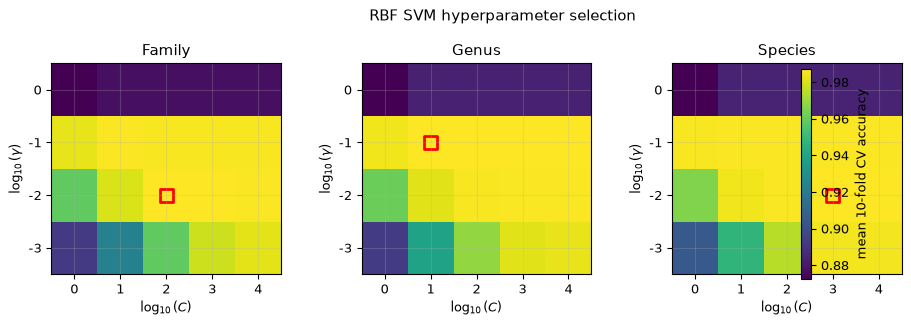

In [5]:
fig, axes = plt.subplots(1,3,figsize=(10.5, 3.4),)

for ax, label in zip(axes, LABELS):
    search = rbf_searches[label]
    results = pd.DataFrame(search.cv_results_)

    heatmap = results.pivot(
        index="param_clf__estimator__gamma", 
        columns="param_clf__estimator__C",
        values="mean_test_score",
    )

    gamma_values = heatmap.index.to_numpy(dtype=float)
    c_values = heatmap.columns.to_numpy(dtype=float)

    image = ax.imshow(
        heatmap.to_numpy(),origin="lower",aspect="auto",cmap="viridis",
    )

    ax.set_xticks(np.arange(len(c_values)))
    ax.set_xticklabels([f"{np.log10(value):.0f}" for value in c_values])

    ax.set_yticks(np.arange(len(gamma_values)))
    ax.set_yticklabels([f"{np.log10(value):.0f}"for value in gamma_values])

    best_c = float(search.best_params_["clf__estimator__C"])

    best_gamma = float(search.best_params_["clf__estimator__gamma"])

    best_x = np.where(c_values == best_c)[0][0]

    best_y = np.where(gamma_values == best_gamma)[0][0]

    ax.scatter(
        best_x, best_y,
        marker="s", facecolors="none", edgecolors="red",
        linewidths=2, s=90,
    )

    ax.set_title(label)
    ax.set_xlabel(r"$\log_{10}(C)$")
    ax.set_ylabel(r"$\log_{10}(\gamma)$")

fig.colorbar(image, ax=axes, label="mean 10-fold CV accuracy", shrink=0.8,)

fig.suptitle("RBF SVM hyperparameter selection")

fig.subplots_adjust(left=0.07, right=0.88, bottom=0.20, top=0.82, wspace=0.35,)

plt.show()

The heatmaps report mean ten-fold cross-validation accuracy for every tested \(C\)-and-\(\gamma\) combination.
The red square marks the selected combination for each label. The final
selected values are reported numerically in the preceding table.

## 1(b)iii. Standardized L1-penalized linear SVMs

`LinearSVC` uses one-vs-rest multiclass handling. The L1 formulation requires `dual=False`; $C$ is selected separately for each label by ten-fold CV over $C\in\{0.1,1,10,100,1000\}$, retaining the interior optima found by the wider preliminary scan.

In [6]:
LINEAR_MAX_ITER, LINEAR_TOL = 100_000, 1e-3
L1_C_GRID = np.array([0.1, 1.0, 10.0, 100.0, 1000.0])

def l1_pipeline(_label):
    return Pipeline([("scale", StandardScaler()), ("clf", LinearSVC(penalty="l1", dual=False, tol=LINEAR_TOL, max_iter=LINEAR_MAX_ITER, random_state=RANDOM_STATE))])

L1_GRID = {"clf__C": L1_C_GRID,}

(l1_table,l1_pred,l1_metrics,l1_models,l1_searches,) = run_searches("L1 linear SVM", l1_pipeline, L1_GRID,)

l1_table["C_on_boundary"] = l1_table["best_C"].isin([L1_C_GRID.min(), L1_C_GRID.max()])

display(
    l1_table[["label","best_C","best_cv_accuracy","test_accuracy","test_macro_f1","C_on_boundary",]
    ].round(4))

overall_cols = ["model", "exact_match", "avg_hamming_distance",
                "hamming_loss", "hamming_score"]
display(pd.DataFrame([l1_metrics])[overall_cols].round(4))

L1 linear SVM: 15.1 seconds


,label,best_C,best_cv_accuracy,test_accuracy,test_macro_f1,C_on_boundary
0,Family,1.0,0.9343,0.9393,0.6992,False
1,Genus,10.0,0.9533,0.9486,0.8520,False
2,Species,1.0,0.9573,0.9606,0.9091,False


,model,exact_match,avg_hamming_distance,hamming_loss,hamming_score
0,L1 linear SVM,0.9176,0.1515,0.0505,0.9495


## 1(b)iv. Leakage-safe SMOTE plus L1 SVM

SMOTE is placed between scaling and classification in an `imblearn` pipeline. Consequently it resamples only the training portion of each CV fold, never validation or test observations. Separate resampling is performed for Family, Genus, and Species. `max_iter` is raised to 100,000 so liblinear converges cleanly at every grid point (any `ConvergenceWarning` would abort execution). Because accuracy can hide performance on rare classes, macro-F1 is also reported; it gives every class equal weight.

In [7]:
def smote_pipeline(_label):
    return ImbPipeline([("scale", StandardScaler()), ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)), ("clf", LinearSVC(penalty="l1", dual=False, tol=LINEAR_TOL, max_iter=LINEAR_MAX_ITER, random_state=RANDOM_STATE))])


with warnings.catch_warnings():
    warnings.simplefilter("error",ConvergenceWarning,)

    (smote_table,smote_pred,smote_metrics,smote_models,smote_searches,) = run_searches(
        "L1 SVM + SMOTE",smote_pipeline,L1_GRID)

smote_table["C_on_boundary"] = smote_table[
    "best_C"].isin([L1_C_GRID.min(), L1_C_GRID.max()])

display(smote_table[
        ["label","best_C","best_cv_accuracy","test_accuracy","test_macro_f1","C_on_boundary",]
    ].round(4))

overall_cols = ["model", "exact_match", "avg_hamming_distance",
                "hamming_loss", "hamming_score"]
display(pd.DataFrame([smote_metrics])[overall_cols].round(4))

L1 SVM + SMOTE: 104.8 seconds


,label,best_C,best_cv_accuracy,test_accuracy,test_macro_f1,C_on_boundary
0,Family,1.0,0.9154,0.9138,0.7835,False
1,Genus,1.0,0.9146,0.9176,0.8121,False
2,Species,1.0,0.9533,0.9602,0.9027,False


,model,exact_match,avg_hamming_distance,hamming_loss,hamming_score
0,L1 SVM + SMOTE,0.8606,0.2084,0.0695,0.9305


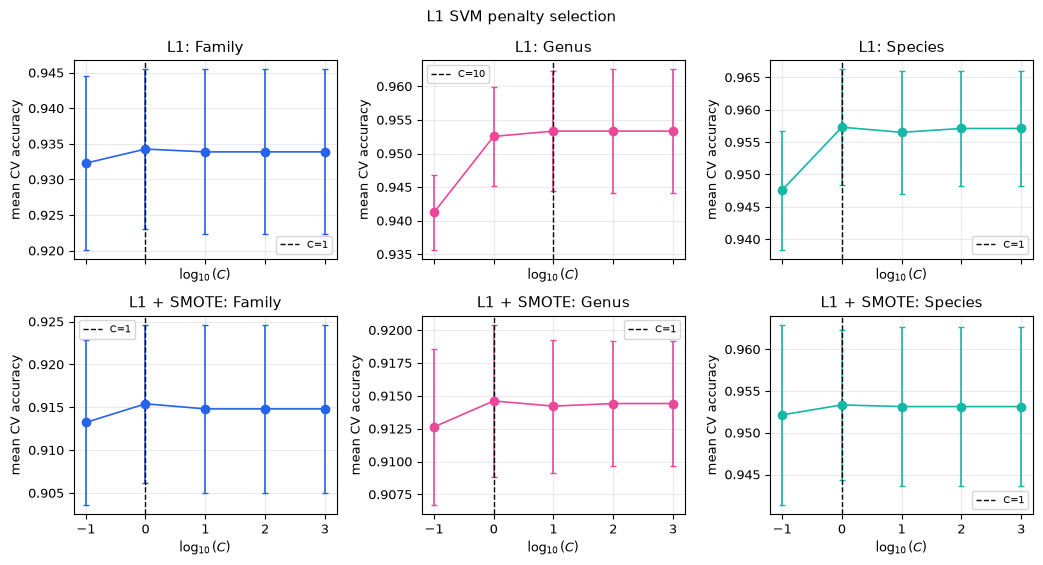

In [8]:
search_groups = [("L1", l1_searches), ("L1 + SMOTE", smote_searches),]

fig, axes = plt.subplots(2,3,figsize=(10.5, 5.7), sharex=True,)

for row, (model_name, searches) in enumerate(
    search_groups
):
    for column, label in enumerate(LABELS):
        ax = axes[row, column]
        search = searches[label]

        results = pd.DataFrame(search.cv_results_)

        c_values = results["param_clf__C"].to_numpy(dtype=float)

        means = results["mean_test_score"].to_numpy()

        standard_deviations = results["std_test_score"].to_numpy()

        order = np.argsort(c_values)

        c_values = c_values[order]
        means = means[order]
        standard_deviations = (standard_deviations[order])

        ax.errorbar(
            np.log10(c_values), means, yerr=standard_deviations, marker="o", capsize=2,
            linewidth=1.2, color=COLORS[column],
        )

        selected_c = float(search.best_params_["clf__C"])

        ax.axvline(
            np.log10(selected_c), color="black",
            linestyle="--", linewidth=1,label=f"C={selected_c:g}",
        )

        ax.set_title(f"{model_name}: {label}")

        ax.set_xlabel(r"$\log_{10}(C)$")
        ax.set_ylabel("mean CV accuracy")
        ax.legend(fontsize=7)

fig.suptitle("L1 SVM penalty selection")

fig.tight_layout()
plt.show()

The curves show mean ten-fold validation
accuracy as a function of \(C\). The dashed line marks the selected value for
each target. These results provide the evidence used to determine the L1
penalty in 1(b)iii and 1(b)iv.

## 1(b)iv. Model comparison and conclusion

In [9]:
comparison = (pd.DataFrame([rbf_metrics, l1_metrics, smote_metrics])
              .sort_values(["hamming_loss", "exact_match"], ascending=[True, False])
              .reset_index(drop=True))
label_cols = ["model"] + [f"{label.lower()}_{metric}" for label in LABELS
                          for metric in ("accuracy", "macro_f1")]
display(comparison[label_cols].set_index("model").T.round(4))

def boundary_hits(table, grids):
    """Return selections that sit on a search-grid boundary."""
    hits = []
    for _, row in table.iterrows():
        for col, grid in grids.items():
            if np.isclose(row[col], (grid.min(), grid.max())).any():
                hits.append(f"{row['label']} {col}={row[col]:g}")
    return hits

grid_map = {
    "RBF SVM": (rbf_table, {"best_C": RBF_C_GRID, "best_gamma": RBF_GAMMA_GRID}),
    "L1 linear SVM": (l1_table, {"best_C": L1_C_GRID}),
    "L1 SVM + SMOTE": (smote_table, {"best_C": L1_C_GRID}),
}
hits = [f"{model} {h}" for model, (table, grids) in grid_map.items()
        for h in boundary_hits(table, grids)]
best = comparison.iloc[0]
smote_delta = smote_metrics["hamming_loss"] - l1_metrics["hamming_loss"]


model,RBF SVM,L1 linear SVM,L1 SVM + SMOTE
family_accuracy,0.9926,0.9393,0.9138
family_macro_f1,0.9892,0.6992,0.7835
genus_accuracy,0.9907,0.9486,0.9176
genus_macro_f1,0.9733,0.8520,0.8121
species_accuracy,0.9898,0.9606,0.9602
species_macro_f1,0.9761,0.9091,0.9027


RBF SVM performs best overall by Hamming loss (0.0090) and has exact match 0.9852. SMOTE changes the L1 Hamming loss by +0.0184. Family macro-F1 changes by +0.0868. Genus macro-F1 changes by -0.0397. Species macro-F1 changes by -0.0010. No selected \(C\) or \(\gamma\) lies on a tested grid boundary; every selected value is interior to its search grid.

## 2. K-means clustering: 50-run Monte Carlo simulation

### 2(a). K-means on the full dataset and automatic selection of $k$

The entire dataset is used because this is unsupervised learning. The supplied MFCCs are already normalized. In each repetition, $k$ is chosen automatically by maximizing the Calinski-Harabasz (CH) index over $k=2,\ldots,50$. CH is undefined for $k=1$, which is why the otherwise permitted singleton solution is excluded. True labels are not used to choose $k$ or fit K-means.

### 2(b). Majority Family, Genus, and Species within each cluster

After clustering, the true labels are read only to determine a majority label triplet for each cluster. Ties are broken deterministically so that all 50 repetitions are reproducible.

In [10]:
def deterministic_mode(values):
    counts = pd.Series(values).value_counts()
    return sorted(counts[counts == counts.max()].index.astype(str))[0]

def cluster_majorities(cluster_ids):
    work = Y.reset_index(drop=True).copy()
    work["cluster"] = cluster_ids
    return work.groupby("cluster")[LABELS].agg(deterministic_mode)

def cluster_label_predictions(cluster_ids, majorities):
    return majorities.loc[cluster_ids, LABELS].reset_index(drop=True)

def one_kmeans_run(rep, x_values):
    best = {"score": -np.inf, "k": None, "clusters": None}
    for k in range(2, 51):
        km = KMeans(n_clusters=k, n_init=3, max_iter=300,
                    random_state=RANDOM_STATE + 1000 * rep + k)
        clusters = km.fit_predict(x_values)
        score = calinski_harabasz_score(x_values, clusters)
        if score > best["score"]:
            best = {"score": score, "k": k, "clusters": clusters}
    majorities = cluster_majorities(best["clusters"])
    pred = cluster_label_predictions(best["clusters"], majorities)
    m = multilabel_metrics(Y[LABELS], pred[LABELS])
    return {"repetition": rep + 1, "selected_k": best["k"],
            "ch_score": best["score"],
            "majority_triplets": majorities.reset_index().to_dict("records"),
            **{key: m[key] for key in ["avg_hamming_distance",
                                          "hamming_loss", "hamming_score"]}}

### 2(c). Hamming distance, Hamming score, and Hamming loss

Each observation receives its cluster's majority triplet. The following cell performs all 50 repetitions and reports the mean and sample standard deviation of the resulting Hamming measures, together with the selected-$k$ distribution.

,mean,std
avg_hamming_distance,0.8956,0.0
hamming_loss,0.2985,0.0
hamming_score,0.7015,0.0


,value
minimum k,2
maximum k,2
modal k,2


Majority triplets for representative repetition 1 (modal k=2):


,cluster,Family,Genus,Species
0,0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,Hylidae,Hypsiboas,HypsiboasCordobae


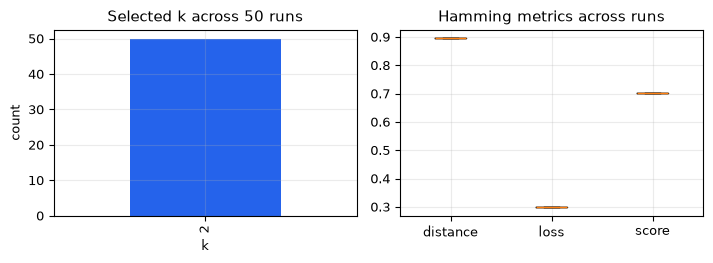

In [11]:
start = time.time()
X_cluster = X.to_numpy(dtype=float)
mc = pd.DataFrame([one_kmeans_run(rep, X_cluster) for rep in range(50)])
metric_cols = ["avg_hamming_distance", "hamming_loss", "hamming_score"]
mc_summary = mc[metric_cols].agg(["mean", "std"]).T
k_summary = pd.Series({"minimum k": mc.selected_k.min(),
                       "maximum k": mc.selected_k.max(),
                       "modal k": mc.selected_k.mode().iat[0]})
display(mc_summary.round(4))
display(k_summary.to_frame("value"))
representative_index = mc.index[mc.selected_k == mc.selected_k.mode().iat[0]][0]
representative_majorities = pd.DataFrame(mc.loc[representative_index, "majority_triplets"])
print(f"Majority triplets for representative repetition {representative_index + 1} "
      f"(modal k={mc.loc[representative_index, 'selected_k']}):")
display(representative_majorities)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7))
mc.selected_k.value_counts().sort_index().plot.bar(ax=axes[0], color=COLORS[0])
axes[0].set(title="Selected k across 50 runs", xlabel="k", ylabel="count")
axes[1].boxplot([mc[c] for c in metric_cols], tick_labels=["distance", "loss", "score"])
axes[1].set_title("Hamming metrics across runs")
fig.tight_layout(); plt.show()
runtime = time.time() - start
sds = {c: mc[c].std(ddof=1) for c in metric_cols}


In all 50 Monte Carlo repetitions, the Calinski-Harabasz criterion selected $k=2$. The resulting evaluation metrics were also identical across repetitions: mean Hamming distance 0.8956, mean Hamming loss 0.2985, and mean Hamming score 0.7015. Consequently, the sample standard deviation of each metric was 0.0. This indicates that the selected value of $k$ and the evaluated labeling performance were stable across the tested random initializations. The 50 unique repetition indices confirm that the simulation loop ran completely.

## 3. ISLR 12.6.2

The dissimilarity matrix is:

| | 1 | 2 | 3 | 4 |
|---:|---:|---:|---:|---:|
| **1** | 0 | 0.30 | 0.40 | 0.70 |
| **2** | 0.30 | 0 | 0.50 | 0.80 |
| **3** | 0.40 | 0.50 | 0 | 0.45 |
| **4** | 0.70 | 0.80 | 0.45 | 0 |

The smallest dissimilarity is $d_{12}=0.30$, so observations 1 and 2 merge first under both complete and single linkage.

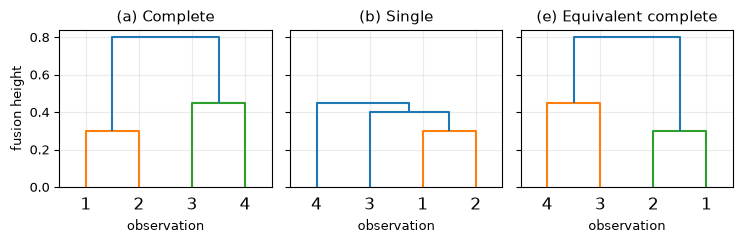

In [12]:
distances = np.array([0.30, 0.40, 0.70, 0.50, 0.80, 0.45])
Z_complete = linkage(distances, method="complete")
Z_single = linkage(distances, method="single")
fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.5), sharey=True)
dendrogram(Z_complete, labels=["1", "2", "3", "4"], ax=axes[0])
dendrogram(Z_single, labels=["1", "2", "3", "4"], ax=axes[1])
dendrogram(Z_complete, labels=["1", "2", "3", "4"],
           count_sort="descending", ax=axes[2])
for ax, title in zip(axes, ["(a) Complete", "(b) Single", "(e) Equivalent complete"]):
    ax.set(title=title, xlabel="observation")
axes[0].set_ylabel("fusion height")
fig.tight_layout(); plt.show()

### 3(a). Complete linkage

Observations 1 and 2 merge at $0.30$. After forming $\{1,2\}$,

$$d_{\mathrm{complete}}(\{1,2\},3)=\max(0.40,0.50)=0.50,$$

and $d_{\mathrm{complete}}(\{1,2\},4)=\max(0.70,0.80)=0.80$. Because $d_{34}=0.45$, observations 3 and 4 merge next. The final fusion is

$$d_{\mathrm{complete}}(\{1,2\},\{3,4\})=\max(0.40,0.70,0.50,0.80)=0.80.$$

Thus, the complete-linkage heights are $0.30$, $0.45$, and $0.80$.

### 3(b). Single linkage

Observations 1 and 2 merge at $0.30$. Next,

$$d_{\mathrm{single}}(\{1,2\},3)=\min(0.40,0.50)=0.40,$$

so observation 3 joins. Finally, $d_{\mathrm{single}}(\{1,2,3\},4)=\min(0.70,0.80,0.45)=0.45$, so observation 4 joins at $0.45$.

### 3(c). Complete-linkage cut

Cutting between $0.45$ and $0.80$ gives $\{1,2\}$ and $\{3,4\}$.

### 3(d). Single-linkage cut

Cutting between $0.40$ and $0.45$ gives $\{1,2,3\}$ and $\{4\}$.

### 3(e). Equivalent dendrogram

The left and right branches at any node may be exchanged without changing cluster membership or fusion height. The third panel is therefore equivalent to part (a), despite its different leaf order.

## References

1. UCI Machine Learning Repository, [*Anuran Calls (MFCCs)*](https://archive.ics.uci.edu/dataset/406/anuran+calls+mfccs).
2. Sorower, M. S., [*A Literature Survey on Algorithms for Multi-label Learning*](https://www.researchgate.net/publication/266888594_A_Literature_Survey_on_Algorithms_for_Multi-label_Learning).
3. scikit-learn, [`hamming_loss`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.hamming_loss.html), SVM, cross-validation, and clustering documentation.
4. imbalanced-learn, [SMOTE and pipeline documentation](https://imbalanced-learn.org/stable/references/over_sampling.html).
5. James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, 2nd ed., Exercise 12.6.2.